# INFO3020 – Telco Customer Churn Analysis
**Câu hỏi nghiên cứu**: Nhóm khách hàng nào (theo loại hợp đồng, dịch vụ internet, thời gian sử dụng) có tỷ lệ rời bỏ cao nhất, để bộ phận chăm sóc khách hàng ưu tiên giữ chân?

---
**Mục lục**
1. Context & Research Question
2. Source & Data Dictionary
3. Cleaning Log
4. Exploratory Analysis (EDA)
5. Key Findings
6. Limitations & Next Steps

> **Cách chạy:** đặt file `WA_Fn-UseC_-Telco-Customer-Churn.csv` **cùng thư mục** với notebook, sau đó chọn *Restart & Run All*.


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 80)

# File csv đặt CÙNG THƯ MỤC với notebook, giữ tên gốc của Kaggle
FILE_PATH = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'

print('Libraries loaded OK')

Libraries loaded OK


---
## PHẦN 1 – Context & Research Question

**Ai dùng phân tích này?** Bộ phận chăm sóc khách hàng (Customer Retention Team) của một công ty viễn thông.

**Giúp quyết định gì?** Ưu tiên nguồn lực giữ chân khách hàng: thay vì áp dụng chương trình ưu đãi cho toàn bộ 7,043 khách, nhắm đúng vào nhóm có nguy cơ rời bỏ cao để tối ưu chi phí.

**Câu hỏi nghiên cứu (1 câu):**
> Nhóm khách hàng nào — phân theo loại hợp đồng, dịch vụ internet, và thời gian sử dụng — có tỷ lệ rời bỏ (churn) cao nhất, và sự khác biệt đó lớn đến mức nào?

**Tại sao quan trọng?** Với tỷ lệ churn 26.5%, nếu giảm được 5 điểm phần trăm thì tương đương giữ lại khoảng 350 khách trong tập 7,043 khách này (dữ liệu là snapshot một thời điểm nên không quy ra theo năm).

---
## PHẦN 2 – Source & Data Dictionary

**Nguồn dữ liệu**: IBM Sample Dataset – Telco Customer Churn  
Tải từ: https://www.kaggle.com/datasets/blastchar/telco-customer-churn  
**Thời điểm thu thập**: Snapshot một thời điểm (không có ngày cụ thể)  
**Cỡ mẫu**: 7,043 khách hàng × 21 cột  
**Đơn vị quan sát**: Một dòng = một khách hàng

| Cột | Kiểu | Mô tả |
|-----|------|-------|
| customerID | str | Mã khách hàng – định danh duy nhất |
| gender | category | Giới tính: Male / Female |
| SeniorCitizen | int→category | Người cao tuổi: 0=No, 1=Yes |
| Partner | category | Có người đồng hành: Yes / No |
| Dependents | category | Có người phụ thuộc: Yes / No |
| tenure | int | Số tháng đã sử dụng dịch vụ (0–72) |
| PhoneService | category | Có dịch vụ điện thoại: Yes / No |
| MultipleLines | category | Nhiều đường dây điện thoại: Yes / No |
| InternetService | category | Loại internet: DSL / Fiber optic / No |
| OnlineSecurity | category | Có bảo mật trực tuyến: Yes / No |
| OnlineBackup | category | Có sao lưu trực tuyến: Yes / No |
| DeviceProtection | category | Có bảo vệ thiết bị: Yes / No |
| TechSupport | category | Có hỗ trợ kỹ thuật: Yes / No |
| StreamingTV | category | Xem TV trực tuyến: Yes / No |
| StreamingMovies | category | Xem phim trực tuyến: Yes / No |
| Contract | category | Loại hợp đồng: Month-to-month / One year / Two year |
| PaperlessBilling | category | Hóa đơn điện tử: Yes / No |
| PaymentMethod | category | Phương thức thanh toán (4 loại) |
| MonthlyCharges | float | Cước phí hàng tháng (USD) |
| TotalCharges | float* | Tổng cước phí (USD) – *ban đầu bị đọc thành str* |
| Churn | category | **Biến mục tiêu**: Rời bỏ dịch vụ: Yes / No |

---
## PHẦN 3 – Cleaning Log

In [2]:
# ── ĐỌC DỮ LIỆU THÔ ─────────────────────────────────────────
df_raw = pd.read_csv(FILE_PATH)
print(f"Kích thước: {df_raw.shape[0]:,} dòng × {df_raw.shape[1]} cột")
print()
print("Kiểu dữ liệu:")
print(df_raw.dtypes)
df_raw.head()

Kích thước: 7,043 dòng × 21 cột

Kiểu dữ liệu:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# ── KIỂM TRA 1: TRÙNG LẶP ───────────────────────────────────
n_dup_id  = df_raw['customerID'].duplicated().sum()
n_dup_row = df_raw.duplicated().sum()
print(f"customerID trùng    : {n_dup_id}")
print(f"Dòng trùng hoàn toàn: {n_dup_row}")
print("→ Kết quả: Không có trùng lặp")

customerID trùng    : 0
Dòng trùng hoàn toàn: 0
→ Kết quả: Không có trùng lặp


In [4]:
# ── KIỂM TRA 2: MISSING VALUES ──────────────────────────────
print("Missing theo pandas (NaN):")
missing = df_raw.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "  → Không có NaN")
print()

# TotalCharges bị đọc sai kiểu → ô trống không bị nhận là NaN
blank_tc = (df_raw['TotalCharges'].str.strip() == '').sum()
print(f"Ô trống thực trong TotalCharges: {blank_tc}")
print(f"Kiểu hiện tại của TotalCharges : {df_raw['TotalCharges'].dtype}")

Missing theo pandas (NaN):
  → Không có NaN

Ô trống thực trong TotalCharges: 11
Kiểu hiện tại của TotalCharges : str


In [5]:
# ── XỬ LÝ 1: TotalCharges → float, điền 0 (thiếu có cấu trúc) ──
df = df_raw.copy()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

mask_nan = df['TotalCharges'].isna()
mask_t0  = df['tenure'] == 0
print(f"Dòng TotalCharges trống   : {mask_nan.sum()}")
print(f"Dòng có tenure = 0        : {mask_t0.sum()}")
print(f"Vừa trống vừa tenure = 0  : {(mask_nan & mask_t0).sum()}")
print(f"Churn của nhóm tenure = 0 : {df.loc[mask_t0, 'Churn'].value_counts().to_dict()}")
print()
print("→ Trống ⇔ tenure = 0 (hai chiều): thiếu có cấu trúc, không phải lỗi nhập liệu")
print("→ Khách mới chưa bị tính cước nên gán 0 là giá trị đúng về nghiệp vụ")

df['TotalCharges'] = df['TotalCharges'].fillna(0)
print(f"\nMissing sau xử lý: {df['TotalCharges'].isna().sum()}")

Dòng TotalCharges trống   : 11
Dòng có tenure = 0        : 11
Vừa trống vừa tenure = 0  : 11
Churn của nhóm tenure = 0 : {'No': 11}

→ Trống ⇔ tenure = 0 (hai chiều): thiếu có cấu trúc, không phải lỗi nhập liệu
→ Khách mới chưa bị tính cước nên gán 0 là giá trị đúng về nghiệp vụ

Missing sau xử lý: 0


In [6]:
# ── XỬ LÝ 2: SeniorCitizen 0/1 → Yes/No ─────────────────────
df['SeniorCitizen'] = df['SeniorCitizen'].map({1: 'Yes', 0: 'No'})
print("SeniorCitizen sau chuẩn hóa:")
print(df['SeniorCitizen'].value_counts())

SeniorCitizen sau chuẩn hóa:
SeniorCitizen
No     5901
Yes    1142
Name: count, dtype: int64


In [7]:
# ── XỬ LÝ 3: Gộp 'No internet/phone service' → 'No' ─────────
internet_cols = ['OnlineSecurity','OnlineBackup','DeviceProtection',
                 'TechSupport','StreamingTV','StreamingMovies']
for col in internet_cols:
    df[col] = df[col].replace('No internet service', 'No')
df['MultipleLines'] = df['MultipleLines'].replace('No phone service', 'No')

print("MultipleLines sau xử lý:")
print(df['MultipleLines'].value_counts())

MultipleLines sau xử lý:
MultipleLines
No     4072
Yes    2971
Name: count, dtype: int64


In [8]:
# ── KIỂM TRA 3: OUTLIER bằng IQR ────────────────────────────
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

print("Kiểm tra outlier theo IQR (ngưỡng 1.5×IQR):")
for col in num_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    lo, hi = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    n_out = ((df[col] < lo) | (df[col] > hi)).sum()
    print(f"  {col}: {n_out} outlier (range hợp lệ: [{lo:.1f}, {hi:.1f}])")

print("\n→ Quyết định: Giữ nguyên – không có giá trị nào nằm ngoài ngưỡng IQR (tenure bị chặn tự nhiên 0–72, cước 18–119 USD hợp lý)")

Kiểm tra outlier theo IQR (ngưỡng 1.5×IQR):
  tenure: 0 outlier (range hợp lệ: [-60.0, 124.0])
  MonthlyCharges: 0 outlier (range hợp lệ: [-46.0, 171.4])
  TotalCharges: 0 outlier (range hợp lệ: [-4683.5, 8868.7])

→ Quyết định: Giữ nguyên – không có giá trị nào nằm ngoài ngưỡng IQR (tenure bị chặn tự nhiên 0–72, cước 18–119 USD hợp lý)


In [9]:
# ── CLEANING LOG – BẢNG TỔNG HỢP ────────────────────────────
def n_iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

n_out   = {c: n_iqr_outliers(df[c]) for c in ['tenure', 'MonthlyCharges', 'TotalCharges']}
n_blank = int((df_raw['TotalCharges'].str.strip() == '').sum())
n_inet  = int((df_raw['OnlineSecurity'] == 'No internet service').sum())
n_phone = int((df_raw['MultipleLines'] == 'No phone service').sum())
churn_pct = (df['Churn'] == 'Yes').mean() * 100

cleaning_log = pd.DataFrame([
    {"#": 1, "Phát hiện": "TotalCharges đọc thành str do có ô trống (isnull() báo 0 NaN)",
     "Số dòng": n_blank, "Hành động": "Ép sang float; điền 0",
     "Lý do": "Thiếu có cấu trúc: toàn bộ dòng trống có tenure=0 (khách mới, chưa bị tính cước)",
     "Kiểm chứng": "Trống ⇔ tenure=0 (11/11 hai chiều); churn của nhóm này: 11 No"},
    {"#": 2, "Phát hiện": "SeniorCitizen mã hóa 0/1, các cột khác Yes/No",
     "Số dòng": len(df_raw), "Hành động": "Map 1→Yes, 0→No",
     "Lý do": "Đồng nhất kiểu phân loại, tránh nhầm khi groupby/vẽ biểu đồ",
     "Kiểm chứng": "value_counts() chỉ còn Yes/No"},
    {"#": 3, "Phát hiện": "'No internet service' ở 6 cột dịch vụ internet; 'No phone service' ở MultipleLines",
     "Số dòng": f"{n_inet:,} dòng × 6 cột / {n_phone:,} dòng", "Hành động": "Gộp về 'No'",
     "Lý do": "Thông tin đã có ở InternetService/PhoneService nên gộp không mất gì",
     "Kiểm chứng": "value_counts() chỉ còn Yes/No"},
    {"#": 4, "Phát hiện": "Trùng customerID / trùng cả dòng",
     "Số dòng": int(df_raw.duplicated().sum()), "Hành động": "Không xử lý",
     "Lý do": "Đã kiểm tra, không có trùng", "Kiểm chứng": "duplicated().sum() == 0"},
    {"#": 5, "Phát hiện": "Outlier tenure / MonthlyCharges / TotalCharges (IQR 1.5×)",
     "Số dòng": f"{n_out['tenure']} / {n_out['MonthlyCharges']} / {n_out['TotalCharges']}",
     "Hành động": "Giữ nguyên",
     "Lý do": "Không có giá trị nằm ngoài ngưỡng IQR; tenure bị chặn tự nhiên 0–72, cước 18–119 USD hợp lý",
     "Kiểm chứng": "n_iqr_outliers() cho 0 ở cả 3 cột"},
    {"#": 6, "Phát hiện": f"Churn lệch lớp: No {100 - churn_pct:.1f}% / Yes {churn_pct:.1f}%",
     "Số dòng": len(df_raw), "Hành động": "Ghi nhận, không xử lý",
     "Lý do": "Không phải lỗi dữ liệu; nhắc lại ở Limitations",
     "Kiểm chứng": "value_counts(normalize=True)"},
]).set_index('#')
display(cleaning_log)

,Phát hiện,Số dòng,Hành động,Lý do,Kiểm chứng
#,,,,,
1,TotalCharges đọc thành str do có ô trống (isnull() báo 0 NaN),11,Ép sang float; điền 0,"Thiếu có cấu trúc: toàn bộ dòng trống có tenure=0 (khách mới, chưa bị tính c...",Trống ⇔ tenure=0 (11/11 hai chiều); churn của nhóm này: 11 No
2,"SeniorCitizen mã hóa 0/1, các cột khác Yes/No",7043,"Map 1→Yes, 0→No","Đồng nhất kiểu phân loại, tránh nhầm khi groupby/vẽ biểu đồ",value_counts() chỉ còn Yes/No
3,'No internet service' ở 6 cột dịch vụ internet; 'No phone service' ở Multipl...,"1,526 dòng × 6 cột / 682 dòng",Gộp về 'No',Thông tin đã có ở InternetService/PhoneService nên gộp không mất gì,value_counts() chỉ còn Yes/No
4,Trùng customerID / trùng cả dòng,0,Không xử lý,"Đã kiểm tra, không có trùng",duplicated().sum() == 0
5,Outlier tenure / MonthlyCharges / TotalCharges (IQR 1.5×),0 / 0 / 0,Giữ nguyên,"Không có giá trị nằm ngoài ngưỡng IQR; tenure bị chặn tự nhiên 0–72, cước 18...",n_iqr_outliers() cho 0 ở cả 3 cột
6,Churn lệch lớp: No 73.5% / Yes 26.5%,7043,"Ghi nhận, không xử lý",Không phải lỗi dữ liệu; nhắc lại ở Limitations,value_counts(normalize=True)


---
## PHẦN 4 – Exploratory Analysis (EDA)
### 4.1 – Thống kê mô tả (4 nhóm thống kê)

In [10]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

# (a) Central tendency
print("=== (a) Central Tendency ===")
ct = df[num_cols].agg(['mean','median']).round(2)
ct.index = ['Mean (trung bình)', 'Median (trung vị)']
display(ct)

# (b) Spread
print("\n=== (b) Spread / Variability ===")
sp = pd.DataFrame({
    col: {'Std': df[col].std(),
          'IQR (Q3−Q1)': df[col].quantile(0.75)-df[col].quantile(0.25),
          'Min': df[col].min(), 'Max': df[col].max()}
    for col in num_cols
}).round(2)
display(sp)

# (c) Shape
print("\n=== (c) Shape / Distribution ===")
sh = pd.DataFrame({
    col: {'Skewness': df[col].skew(), 'Kurtosis': df[col].kurt()}
    for col in num_cols
}).round(3)
display(sh)
print("  Skewness >0 = lệch phải | <0 = lệch trái | ~0 = đối xứng")

# (d) Relationship
print("\n=== (d) Relationship – Tương quan Pearson ===")
display(df[num_cols].corr().round(2))
print("  ⚠ Tương quan ≠ nhân quả – xem phân tích theo nhóm bên dưới")

=== (a) Central Tendency ===


,tenure,MonthlyCharges,TotalCharges
Mean (trung bình),32.37,64.76,2279.73
Median (trung vị),29.00,70.35,1394.55



=== (b) Spread / Variability ===


,tenure,MonthlyCharges,TotalCharges
Std,24.56,30.09,2266.79
IQR (Q3−Q1),46.00,54.35,3388.05
Min,0.00,18.25,0.00
Max,72.00,118.75,8684.80



=== (c) Shape / Distribution ===


,tenure,MonthlyCharges,TotalCharges
Skewness,0.240,-0.221,0.963
Kurtosis,-1.387,-1.257,-0.229


  Skewness >0 = lệch phải | <0 = lệch trái | ~0 = đối xứng

=== (d) Relationship – Tương quan Pearson ===


,tenure,MonthlyCharges,TotalCharges
tenure,1.00,0.25,0.83
MonthlyCharges,0.25,1.00,0.65
TotalCharges,0.83,0.65,1.00


  ⚠ Tương quan ≠ nhân quả – xem phân tích theo nhóm bên dưới


### 4.1b – Bảng tóm tắt + histogram TotalCharges (dùng cho slide)

,Trung bình,Trung vị,Độ lệch chuẩn,Skewness
tenure,32.37,29.00,24.56,0.24
MonthlyCharges,64.76,70.35,30.09,-0.22
TotalCharges,2279.73,1394.55,2266.79,0.96


Tương quan tenure – TotalCharges: 0.83


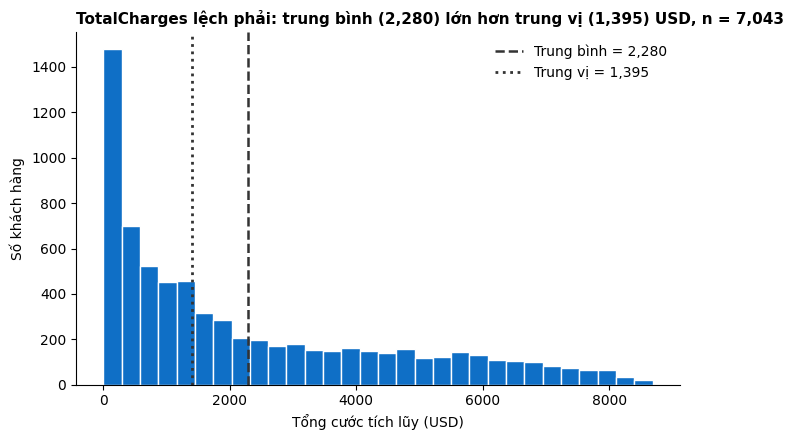

In [11]:
# ── 4.1b: Bảng tóm tắt + histogram TotalCharges (dùng cho slide) ──
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
summary = pd.DataFrame({
    'Trung bình':    df[num_cols].mean(),
    'Trung vị':      df[num_cols].median(),
    'Độ lệch chuẩn': df[num_cols].std(),
    'Skewness':      df[num_cols].skew(),
}).round(2)
display(summary)
print(f"Tương quan tenure – TotalCharges: {df['tenure'].corr(df['TotalCharges']):.2f}")

m, md = df['TotalCharges'].mean(), df['TotalCharges'].median()
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(df['TotalCharges'], bins=30, color='#0F6FC6', edgecolor='white')
ax.axvline(m,  color='#333333', linestyle='--', lw=1.8, label=f'Trung bình = {m:,.0f}')
ax.axvline(md, color='#333333', linestyle=':',  lw=2.0, label=f'Trung vị = {md:,.0f}')
ax.set_title(f'TotalCharges lệch phải: trung bình ({m:,.0f}) lớn hơn trung vị ({md:,.0f}) USD, n = {len(df):,}',
             fontsize=11, fontweight='bold', loc='left')
ax.set_xlabel('Tổng cước tích lũy (USD)')
ax.set_ylabel('Số khách hàng')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('hist_totalcharges.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.2 – Phân tích theo nhóm Churn

In [12]:
# Tỷ lệ Churn tổng
print("Tỷ lệ Churn tổng thể:")
print(df['Churn'].value_counts(normalize=True).mul(100).round(1).astype(str) + '%')
print()

# Thống kê số liên tục theo nhóm Churn
print("Thống kê theo nhóm Churn:")
display(
    df.groupby('Churn')[num_cols]
      .agg(['mean','median'])
      .round(2)
)

Tỷ lệ Churn tổng thể:
Churn
No     73.5%
Yes    26.5%
Name: proportion, dtype: str

Thống kê theo nhóm Churn:


tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43      2549.91  1679.52
Yes    17.98   10.0          74.44  79.65      1531.80   703.55

In [13]:
# Tỷ lệ Churn theo các biến phân loại
cat_vars = ['Contract', 'InternetService', 'PaymentMethod',
            'SeniorCitizen', 'Partner', 'Dependents',
            'PhoneService', 'PaperlessBilling']

print("Tỷ lệ Churn theo từng nhóm:")
for col in cat_vars:
    tbl = df.groupby(col)['Churn'].apply(
        lambda x: (x == 'Yes').mean() * 100
    ).round(1)
    print(f"\n{col}:")
    print(tbl.sort_values(ascending=False).astype(str) + '%')

Tỷ lệ Churn theo từng nhóm:

Contract:
Contract
Month-to-month    42.7%
One year          11.3%
Two year           2.8%
Name: Churn, dtype: str

InternetService:
InternetService
Fiber optic    41.9%
DSL            19.0%
No              7.4%
Name: Churn, dtype: str

PaymentMethod:
PaymentMethod
Electronic check             45.3%
Mailed check                 19.1%
Bank transfer (automatic)    16.7%
Credit card (automatic)      15.2%
Name: Churn, dtype: str

SeniorCitizen:
SeniorCitizen
Yes    41.7%
No     23.6%
Name: Churn, dtype: str

Partner:
Partner
No     33.0%
Yes    19.7%
Name: Churn, dtype: str

Dependents:
Dependents
No     31.3%
Yes    15.5%
Name: Churn, dtype: str

PhoneService:
PhoneService
Yes    26.7%
No     24.9%
Name: Churn, dtype: str

PaperlessBilling:
PaperlessBilling
Yes    33.6%
No     16.3%
Name: Churn, dtype: str


### 4.3 – 5 Biểu đồ chính

**Biểu đồ 1**: Khách hợp đồng tháng churn gấp ~15 lần khách hợp đồng 2 năm (42.7% vs 2.8%)

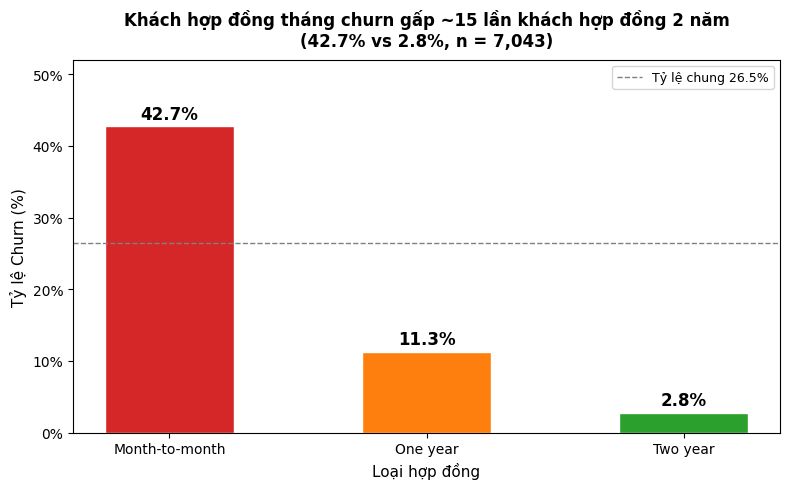

Caption: Tỷ lệ churn theo loại hợp đồng. Nguồn: IBM Telco Dataset (n = 7,043).


In [14]:
# ── BIỂU ĐỒ 1: Tỷ lệ Churn theo Contract ────────────────────
churn_contract = df.groupby('Contract')['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
).round(1).reset_index()
churn_contract.columns = ['Contract', 'ChurnRate']
churn_contract = churn_contract.sort_values('ChurnRate', ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#d62728', '#ff7f0e', '#2ca02c']
bars = ax.bar(churn_contract['Contract'], churn_contract['ChurnRate'],
              color=colors, edgecolor='white', width=0.5)

for bar, val in zip(bars, churn_contract['ChurnRate']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{val}%', ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_title(
    'Khách hợp đồng tháng churn gấp ~15 lần khách hợp đồng 2 năm\n(42.7% vs 2.8%, n = 7,043)',
    fontsize=12, fontweight='bold', pad=10)
ax.set_xlabel('Loại hợp đồng', fontsize=11)
ax.set_ylabel('Tỷ lệ Churn (%)', fontsize=11)
ax.set_ylim(0, 52)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
ax.axhline(26.5, color='gray', linestyle='--', linewidth=1, label='Tỷ lệ chung 26.5%')
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('bieu_do_1_contract.png', dpi=150, bbox_inches='tight')
plt.show()
print('Caption: Tỷ lệ churn theo loại hợp đồng. Nguồn: IBM Telco Dataset (n = 7,043).')

**Biểu đồ 2**: Khách dùng Fiber optic có tỷ lệ churn cao nhất (41.9%), gấp ~6 lần khách không dùng internet (7.4%)

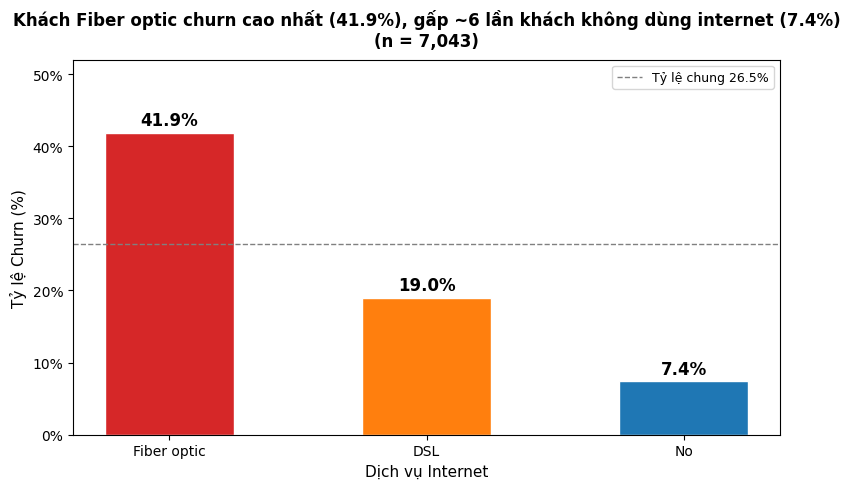

Caption: Tỷ lệ churn theo loại dịch vụ internet. Nguồn: IBM Telco Dataset (n = 7,043).


In [15]:
# ── BIỂU ĐỒ 2: Tỷ lệ Churn theo InternetService ─────────────
churn_inet = df.groupby('InternetService')['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
).round(1).reset_index()
churn_inet.columns = ['InternetService', 'ChurnRate']
churn_inet = churn_inet.sort_values('ChurnRate', ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
palette = ['#d62728', '#ff7f0e', '#1f77b4']
bars = ax.bar(churn_inet['InternetService'], churn_inet['ChurnRate'],
              color=palette, edgecolor='white', width=0.5)

for bar, val in zip(bars, churn_inet['ChurnRate']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{val}%', ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_title(
    'Khách Fiber optic churn cao nhất (41.9%), gấp ~6 lần khách không dùng internet (7.4%)\n(n = 7,043)',
    fontsize=12, fontweight='bold', pad=10)
ax.set_xlabel('Dịch vụ Internet', fontsize=11)
ax.set_ylabel('Tỷ lệ Churn (%)', fontsize=11)
ax.set_ylim(0, 52)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
ax.axhline(26.5, color='gray', linestyle='--', linewidth=1, label='Tỷ lệ chung 26.5%')
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('bieu_do_2_internet.png', dpi=150, bbox_inches='tight')
plt.show()
print('Caption: Tỷ lệ churn theo loại dịch vụ internet. Nguồn: IBM Telco Dataset (n = 7,043).')

**Biểu đồ 3**: 55% khách churn rời đi trong 12 tháng đầu; tỷ lệ churn giảm từ 47.4% (0–12 tháng) xuống 9.5% (49–72 tháng)

Tỷ lệ churn theo nhóm tenure:


,n,churn_rate
TenureGroup,,
0–12,2186,47.4
13–24,1024,28.7
25–48,1594,20.4
49–72,2239,9.5


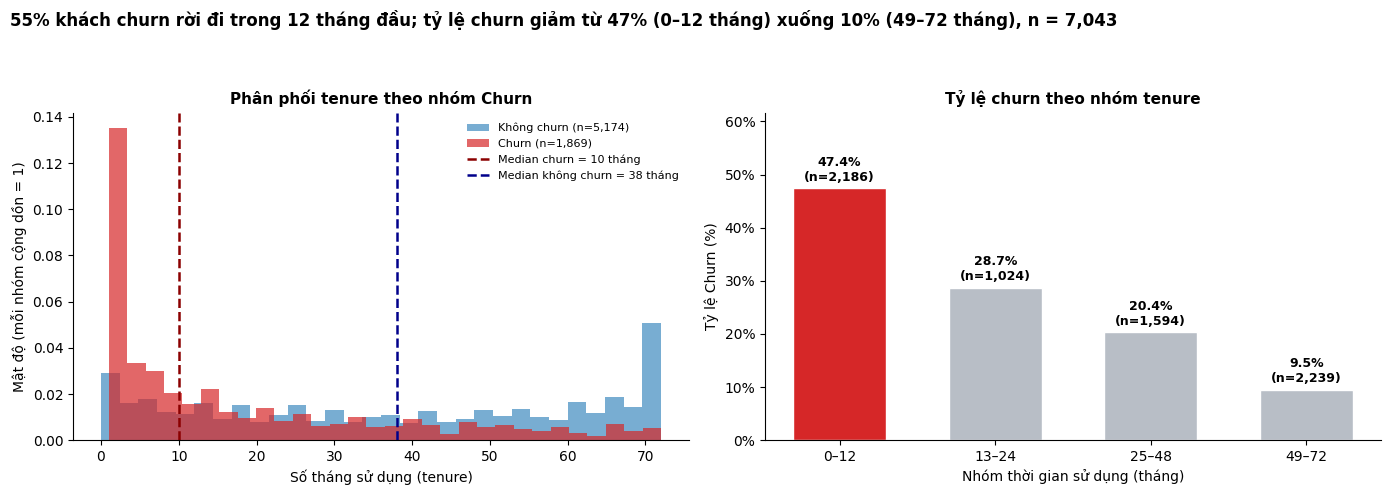

Caption: Phân phối tenure và tỷ lệ churn theo nhóm tenure. Nguồn: IBM Telco Dataset (n = 7,043).


In [16]:
# ── BIỂU ĐỒ 3: Tenure theo nhóm Churn + tỷ lệ churn theo nhóm tenure ──
df['TenureGroup'] = pd.cut(df['tenure'], bins=[-1, 12, 24, 48, 72],
                           labels=['0–12', '13–24', '25–48', '49–72'])
tg = (df.groupby('TenureGroup', observed=True)['Churn']
        .agg(n='size', churn_rate=lambda s: (s == 'Yes').mean() * 100).round(1))
print("Tỷ lệ churn theo nhóm tenure:")
display(tg)
rate = tg['churn_rate']

yes = df.loc[df['Churn'] == 'Yes', 'tenure']
no  = df.loc[df['Churn'] == 'No',  'tenure']
share12 = (yes <= 12).mean() * 100

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f"{share12:.0f}% khách churn rời đi trong 12 tháng đầu; tỷ lệ churn giảm từ "
             f"{rate.iloc[0]:.0f}% (0–12 tháng) xuống {rate.iloc[-1]:.0f}% (49–72 tháng), n = {len(df):,}",
             fontsize=12, fontweight='bold', x=0.01, ha='left')

a1.hist(no,  bins=30, alpha=0.6, color='#1f77b4', density=True, label=f'Không churn (n={len(no):,})')
a1.hist(yes, bins=30, alpha=0.7, color='#d62728', density=True, label=f'Churn (n={len(yes):,})')
a1.axvline(yes.median(), color='darkred',  linestyle='--', lw=1.8, label=f'Median churn = {yes.median():.0f} tháng')
a1.axvline(no.median(),  color='darkblue', linestyle='--', lw=1.8, label=f'Median không churn = {no.median():.0f} tháng')
a1.set_xlabel('Số tháng sử dụng (tenure)')
a1.set_ylabel('Mật độ (mỗi nhóm cộng dồn = 1)')
a1.set_title('Phân phối tenure theo nhóm Churn', fontsize=11, fontweight='bold')
a1.legend(fontsize=8, frameon=False)

colors = ['#d62728'] + ['#B8BEC6'] * (len(rate) - 1)
bars = a2.bar(rate.index.astype(str), rate.values, color=colors, edgecolor='white', width=0.6)
for b, n in zip(bars, tg['n']):
    a2.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.8,
            f"{b.get_height():.1f}%\n(n={n:,})", ha='center', va='bottom', fontsize=9, fontweight='bold')
a2.set_ylim(0, rate.max() * 1.3)
a2.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
a2.set_xlabel('Nhóm thời gian sử dụng (tháng)')
a2.set_ylabel('Tỷ lệ Churn (%)')
a2.set_title('Tỷ lệ churn theo nhóm tenure', fontsize=11, fontweight='bold')
for ax in (a1, a2):
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig('bieu_do_3_tenure.png', dpi=150, bbox_inches='tight')
plt.show()
print('Caption: Phân phối tenure và tỷ lệ churn theo nhóm tenure. Nguồn: IBM Telco Dataset (n = 7,043).')

**Biểu đồ 4**: Khách churn trả cước cao hơn khách không churn (median $79.7 vs $64.4/tháng)

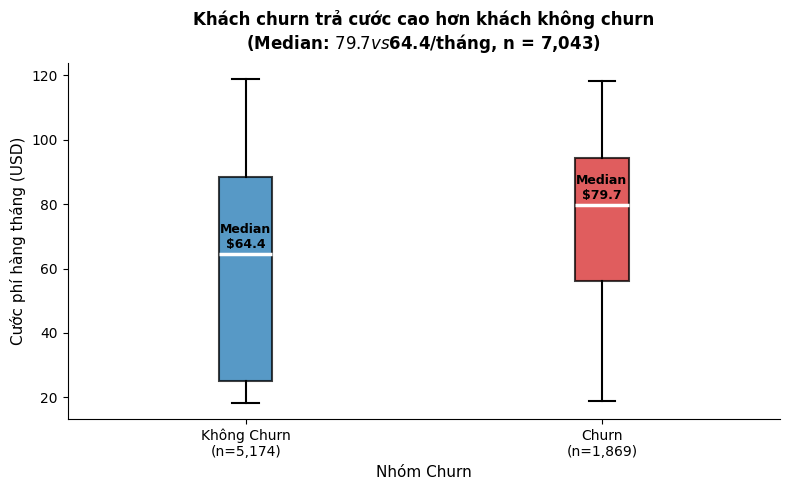

Caption: Phân phối MonthlyCharges theo nhóm Churn. Nguồn: IBM Telco Dataset (n = 7,043).


In [17]:
# ── BIỂU ĐỒ 4: MonthlyCharges theo nhóm Churn (Boxplot) ─────
fig, ax = plt.subplots(figsize=(8, 5))

d_no  = df.loc[df['Churn'] == 'No',  'MonthlyCharges']
d_yes = df.loc[df['Churn'] == 'Yes', 'MonthlyCharges']
colors = ['#1f77b4', '#d62728']

bp = ax.boxplot([d_no, d_yes], patch_artist=True,
                medianprops=dict(color='white', linewidth=2.5),
                boxprops=dict(linewidth=1.5),
                whiskerprops=dict(linewidth=1.5),
                capprops=dict(linewidth=1.5))
ax.set_xticks([1, 2])
ax.set_xticklabels([f'Không Churn\n(n={len(d_no):,})', f'Churn\n(n={len(d_yes):,})'])
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

# Giá trị median ghi trên hộp
for i, d in enumerate([d_no, d_yes], 1):
    ax.text(i, d.median() + 1, f'Median\n${d.median():.1f}', ha='center', va='bottom',
            fontsize=9, fontweight='bold', color='black')

med = df.groupby('Churn')['MonthlyCharges'].median()
ax.set_title(f"Khách churn trả cước cao hơn khách không churn\n"
             f"(Median: ${med['Yes']:.1f} vs ${med['No']:.1f}/tháng, n = {len(df):,})",
             fontsize=12, fontweight='bold', pad=10)
ax.set_ylabel('Cước phí hàng tháng (USD)', fontsize=11)
ax.set_xlabel('Nhóm Churn', fontsize=11)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('bieu_do_4_monthly.png', dpi=150, bbox_inches='tight')
plt.show()
print('Caption: Phân phối MonthlyCharges theo nhóm Churn. Nguồn: IBM Telco Dataset (n = 7,043).')

**Biểu đồ 5**: Fiber optic + hợp đồng tháng là tổ hợp có churn cao nhất (54.6%); tách theo Contract, Fiber vẫn cao hơn DSL, nhưng giá và chất lượng mạng chưa được kiểm soát

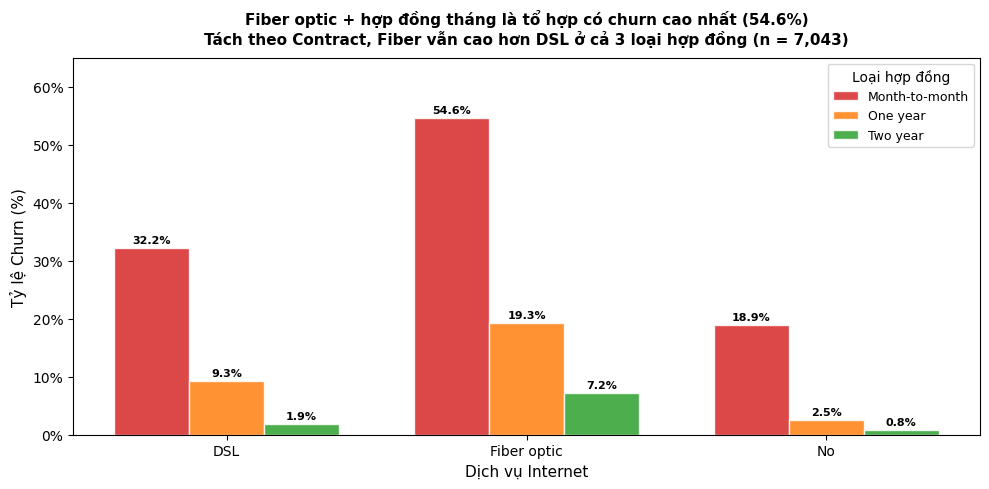

Caption: Tỷ lệ churn theo InternetService và Contract. Nguồn: IBM Telco Dataset (n = 7,043).

Contract         Month-to-month  One year  Two year
InternetService                                    
DSL                        32.2       9.3       1.9
Fiber optic                54.6      19.3       7.2
No                         18.9       2.5       0.8


In [18]:
# ── BIỂU ĐỒ 5: Churn rate theo InternetService × Contract ────
# (Kiểm tra confounder: Fiber churn cao vì dịch vụ hay vì hay dùng hợp đồng tháng?)
pivot = df.groupby(['InternetService','Contract'])['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
).round(1).unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(pivot.index))
width = 0.25
colors_c = ['#d62728', '#ff7f0e', '#2ca02c']

for i, (contract, color) in enumerate(zip(pivot.columns, colors_c)):
    vals = pivot[contract]
    bars = ax.bar(x + i*width, vals, width, label=contract, color=color, alpha=0.85, edgecolor='white')
    for bar, val in zip(bars, vals):
        if val > 0:
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                    f'{val}%', ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.set_title(
    'Fiber optic + hợp đồng tháng là tổ hợp có churn cao nhất (54.6%)\n'
    'Tách theo Contract, Fiber vẫn cao hơn DSL ở cả 3 loại hợp đồng (n = 7,043)',
    fontsize=11, fontweight='bold', pad=10)
ax.set_xticks(x + width)
ax.set_xticklabels(pivot.index, fontsize=10)
ax.set_ylabel('Tỷ lệ Churn (%)', fontsize=11)
ax.set_xlabel('Dịch vụ Internet', fontsize=11)
ax.set_ylim(0, 65)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
ax.legend(title='Loại hợp đồng', fontsize=9)

plt.tight_layout()
plt.savefig('bieu_do_5_fiber_contract.png', dpi=150, bbox_inches='tight')
plt.show()
print('Caption: Tỷ lệ churn theo InternetService và Contract. Nguồn: IBM Telco Dataset (n = 7,043).')
print()
print(pivot)

### 4.4 – Kiểm tra confounder (phục vụ Biểu đồ 5 và Key Finding 2, 5)
Tách theo Contract chỉ kiểm soát **một** confounder. Ô dưới đây cho thấy mức độ trộn lẫn giữa InternetService, Contract, giá và PaymentMethod.

In [19]:
# ── KIỂM TRA CONFOUNDER ─────────────────────────────────────
print("Số khách ở mỗi ô (InternetService × Contract):")
display(df.groupby(['InternetService', 'Contract']).size().unstack())

print("\nTỷ lệ loại hợp đồng trong từng nhóm Internet (%):")
display(pd.crosstab(df['InternetService'], df['Contract'], normalize='index').mul(100).round(1))

print("\nCước hàng tháng theo InternetService (USD):")
display(df.groupby('InternetService')['MonthlyCharges'].agg(['mean', 'median']).round(1))

print("\nPaymentMethod cũng bị trộn với Contract – tỷ lệ loại hợp đồng theo PaymentMethod (%):")
display(pd.crosstab(df['PaymentMethod'], df['Contract'], normalize='index').mul(100).round(1))

fm = df[(df['InternetService'] == 'Fiber optic') & (df['Contract'] == 'Month-to-month')]
print("\nMedian cước trong riêng nhóm Fiber + hợp đồng tháng, theo Churn (USD):")
display(fm.groupby('Churn')['MonthlyCharges'].median().round(1))

Số khách ở mỗi ô (InternetService × Contract):


Contract,Month-to-month,One year,Two year
InternetService,,,
DSL,1223,570,628
Fiber optic,2128,539,429
No,524,364,638



Tỷ lệ loại hợp đồng trong từng nhóm Internet (%):


Contract,Month-to-month,One year,Two year
InternetService,,,
DSL,50.5,23.5,25.9
Fiber optic,68.7,17.4,13.9
No,34.3,23.9,41.8



Cước hàng tháng theo InternetService (USD):


,mean,median
InternetService,,
DSL,58.1,56.2
Fiber optic,91.5,91.7
No,21.1,20.2



PaymentMethod cũng bị trộn với Contract – tỷ lệ loại hợp đồng theo PaymentMethod (%):


Contract,Month-to-month,One year,Two year
PaymentMethod,,,
Bank transfer (automatic),38.1,25.3,36.5
Credit card (automatic),35.7,26.1,38.2
Electronic check,78.2,14.7,7.1
Mailed check,55.4,20.9,23.7



Median cước trong riêng nhóm Fiber + hợp đồng tháng, theo Churn (USD):


Churn
No     87.8
Yes    85.4
Name: MonthlyCharges, dtype: float64

---
## PHẦN 5 – Key Findings

**Trả lời câu hỏi nghiên cứu:** Nhóm có churn cao nhất là khách mới **0–12 tháng (47.4%)**, khách **hợp đồng tháng (42.7%)** và khách **Fiber optic (41.9%)**; tổ hợp **Fiber + hợp đồng tháng lên tới 54.6%**. Mức chênh giữa nhóm cao nhất và thấp nhất lớn nhất ở Contract (gấp ~15 lần), rồi InternetService (~6 lần), PaymentMethod (~3 lần).

1. **[Biểu đồ 1]** Loại hợp đồng có mức chênh churn lớn nhất giữa các nhóm: hợp đồng tháng 42.7%, cao gấp ~15 lần hợp đồng 2 năm (2.8%). Đây là nhóm nên ưu tiên can thiệp đầu tiên.
2. **[Biểu đồ 2]** Khách Fiber optic có churn 41.9%, gấp ~6 lần nhóm không dùng internet (7.4%). Tuy nhiên mối quan hệ này có thể bị confound bởi loại hợp đồng (68.7% khách Fiber dùng hợp đồng tháng, DSL chỉ 50.5%) và cước phí (Fiber trung bình $91.5/tháng so với DSL $58.1).
3. **[Biểu đồ 3]** 55% khách churn rời đi trong 12 tháng đầu. Churn là 47.4% ở nhóm 0–12 tháng so với 9.5% ở nhóm 49–72 tháng; median tenure của nhóm churn là 10 tháng so với 38 tháng của nhóm không churn. Gợi ý ưu tiên chăm sóc khách mới trong năm đầu.
4. **[Biểu đồ 4]** Khách churn trả cước cao hơn (median $79.7 so với $64.4/tháng). Cước cao có liên quan đến rời bỏ, nhưng cần kiểm soát loại dịch vụ trước khi kết luận, vì Fiber vừa đắt vừa churn cao.
5. **[Biểu đồ 5]** Fiber + hợp đồng tháng có churn 54.6%. Tách theo Contract, Fiber vẫn cao hơn DSL ở cả 3 loại hợp đồng (54.6% vs 32.2%; 19.3% vs 9.3%; 7.2% vs 1.9%). Điều này cho thấy Contract không giải thích hết sự chênh lệch, nhưng giá và chất lượng mạng chưa được kiểm soát nên **chưa kết luận được nguyên nhân**.

> ⚠ **Lưu ý diễn giải:** các phát hiện trên là **tương quan, không phải nhân quả**. Chỉ có thể nói "Fiber optic *liên quan đến* churn cao hơn", không nói "Fiber optic *làm* khách bỏ đi".


---
## PHẦN 6 – Limitations & Next Steps

### Limitations

1. **Dữ liệu snapshot, không có chiều thời gian.** Không có ngày tháng nên không phân tích được xu hướng hay mùa vụ. *Ảnh hưởng:* không biết churn đang tăng hay giảm; mọi so sánh chỉ ở một thời điểm.
2. **Không có lý do rời bỏ.** Chỉ nói được *ai* bỏ đi, không nói được *vì sao*. *Ảnh hưởng:* mọi giải thích nguyên nhân (Key Finding 2, 4, 5) đều là suy luận.
3. **Thiếu confounder tiềm năng:** giá đối thủ, chất lượng mạng, số lần khiếu nại, vị trí địa lý. *Ảnh hưởng:* không xác định được Fiber optic thực sự có vấn đề hay chỉ vì nhóm khách Fiber có đặc điểm khác (giá cao, hợp đồng ngắn).
4. **Churn lệch lớp (No 73.5% / Yes 26.5%).** Không ảnh hưởng EDA vì dùng tỷ lệ trong từng nhóm; nếu xây mô hình dự đoán cần class weight hoặc SMOTE.
5. **Cỡ mẫu nhỏ ở một số ô khi chia nhóm** (ví dụ Fiber × hợp đồng 2 năm, n = 429), và chưa có khoảng tin cậy. *Ảnh hưởng:* chênh lệch giữa các ô nhỏ cần đọc thận trọng.
6. **Dữ liệu mẫu công khai của IBM**, không đại diện cho một công ty viễn thông cụ thể nên khó khái quát hóa.

### Next steps

1. Thu thập thêm: lý do rời bỏ (exit survey), lịch sử khiếu nại, điểm NPS.
2. Thêm chiều thời gian: theo dõi cohort khách hàng theo tháng gia nhập.
3. Kiểm soát đồng thời nhiều biến bằng logistic regression để tách tác động của giá, hợp đồng và loại dịch vụ.
4. Xây dựng mô hình dự đoán (Logistic Regression, Random Forest) để chấm điểm nguy cơ churn, nếu phạm vi môn học yêu cầu.


---
## PHỤ LỤC – Kiểm tra độ nhạy và câu hỏi Viva

In [20]:
# ── KIỂM TRA ĐỘ NHẠY (phục vụ Viva Q1 và Q3) ────────────────

# Q1: nếu XÓA 11 dòng tenure = 0 thay vì điền 0 thì tỷ lệ churn có đổi không?
churn_fill = (df['Churn'] == 'Yes').mean() * 100
churn_drop = (df.loc[df['tenure'] > 0, 'Churn'] == 'Yes').mean() * 100
print(f"Tỷ lệ churn: điền 0 = {churn_fill:.2f}% | xóa 11 dòng = {churn_drop:.2f}%")

# Q3: xóa ngẫu nhiên 10% dòng, lặp 200 lần
rows, fiber_order_ok = [], 0
for seed in range(200):
    d = df.sample(frac=0.9, random_state=seed)
    rows.append(d.groupby('Contract')['Churn'].apply(lambda s: (s == 'Yes').mean() * 100))
    r = d.groupby('InternetService')['Churn'].apply(lambda s: (s == 'Yes').mean())
    fiber_order_ok += int(r['Fiber optic'] > r['DSL'] > r['No'])

print("\nTỷ lệ churn theo Contract qua 200 lần xóa ngẫu nhiên 10% (min – max, %):")
display(pd.DataFrame(rows).agg(['min', 'max']).round(1))
print(f"Thứ tự Fiber > DSL > No giữ nguyên ở {fiber_order_ok}/200 lần")

Tỷ lệ churn: điền 0 = 26.54% | xóa 11 dòng = 26.58%



Tỷ lệ churn theo Contract qua 200 lần xóa ngẫu nhiên 10% (min – max, %):


Contract,Month-to-month,One year,Two year
min,42.0,10.3,2.5
max,43.4,11.9,3.1


Thứ tự Fiber > DSL > No giữ nguyên ở 200/200 lần


### Chuẩn bị Viva

**Q1. Vì sao xử lý missing TotalCharges bằng cách điền 0 mà không xóa?**
Cả 11 dòng trống đều có tenure = 0 (khách mới, chưa bị tính cước), nên giá trị 0 đúng về nghiệp vụ. Xóa sẽ mất nhóm khách mới. Kiểm tra độ nhạy ở ô trên: tỷ lệ churn là 26.54% nếu điền 0 và 26.58% nếu xóa, nên kết luận không đổi.

**Q2. Cơ chế missing của cột này là gì? Bằng chứng?**
Thiếu có cấu trúc (structural missing): ô trống được quyết định hoàn toàn bởi tenure = 0, không ngẫu nhiên và không phải lỗi nhập liệu. Bằng chứng hai chiều: 11/11 dòng trống có tenure = 0, và 11/11 dòng có tenure = 0 đều trống. (Không gọi là MNAR vì MNAR nghĩa là xác suất thiếu phụ thuộc vào chính giá trị bị thiếu.)

**Q3. Nếu xóa ngẫu nhiên 10% dòng thì kết luận có đổi không?**
Không. Qua 200 lần xóa ngẫu nhiên 10%, churn của hợp đồng tháng dao động 42.0–43.4%, một năm 10.3–11.9%, hai năm 2.5–3.1%; thứ tự Fiber > DSL > No giữ nguyên 200/200 lần. Con số dao động dưới 1.5 điểm %, xu hướng không đổi.

**Q4. Biểu đồ này có thể đánh lừa người đọc vội ở chỗ nào?**
- *Biểu đồ 1, 2:* cột tỷ lệ không cho thấy cỡ nhóm; hợp đồng 2 năm churn 2.8% nhưng chỉ khoảng 48 khách.
- *Biểu đồ 3:* histogram dùng mật độ nên hai nhóm trông cùng cỡ dù churn chỉ 1,869 khách so với 5,174; panel phải có ghi n để bù. Tenure của nhóm churn là thời gian đến lúc rời đi, còn khách chưa churn vẫn đang ở lại (dữ liệu bị cắt cụt).
- *Biểu đồ 4:* chênh cước dễ bị đọc là "giá cao gây churn", trong khi Fiber vừa đắt vừa churn cao.
- *Biểu đồ 5:* một số ô nhỏ (Fiber × 2 năm, n = 429), không có khoảng tin cậy, và chưa kiểm soát giá.

**Q5. Confounder hợp lý cho mối quan hệ Fiber optic – Churn là gì?**
(1) Contract: 68.7% khách Fiber dùng hợp đồng tháng so với 50.5% ở DSL. (2) MonthlyCharges: Fiber trung bình $91.5 so với DSL $58.1. (3) Chất lượng mạng, khiếu nại, giá đối thủ: không có trong dữ liệu. Tách theo Contract thì Fiber vẫn cao hơn DSL ở cả 3 loại hợp đồng, nên Contract không giải thích hết; nhưng giá và chất lượng mạng chưa kiểm soát được nên chưa kết luận nhân quả. Quan sát thêm: trong riêng nhóm Fiber + hợp đồng tháng, median cước của khách churn ($85.4) thấp hơn khách ở lại ($87.8), nên giá khó là lời giải đơn giản duy nhất.

**Câu hỏi có thể bị hỏi thêm**
- *PaymentMethod:* Electronic check có churn 45.3% (cao nhất trong các nhóm đơn lẻ), nhưng 78.2% khách dùng Electronic check đang ở hợp đồng tháng, nên cũng bị trộn với Contract.
- *Tương quan tenure–TotalCharges = 0.83:* TotalCharges gần như bằng tenure × MonthlyCharges, hai cột chồng thông tin nên cần lưu ý nếu làm mô hình.
